In [2]:
import geopandas as gpd

print("GeoPandas installed successfully!")
print("Version:", gpd.__version__)

GeoPandas installed successfully!
Version: 1.2.0


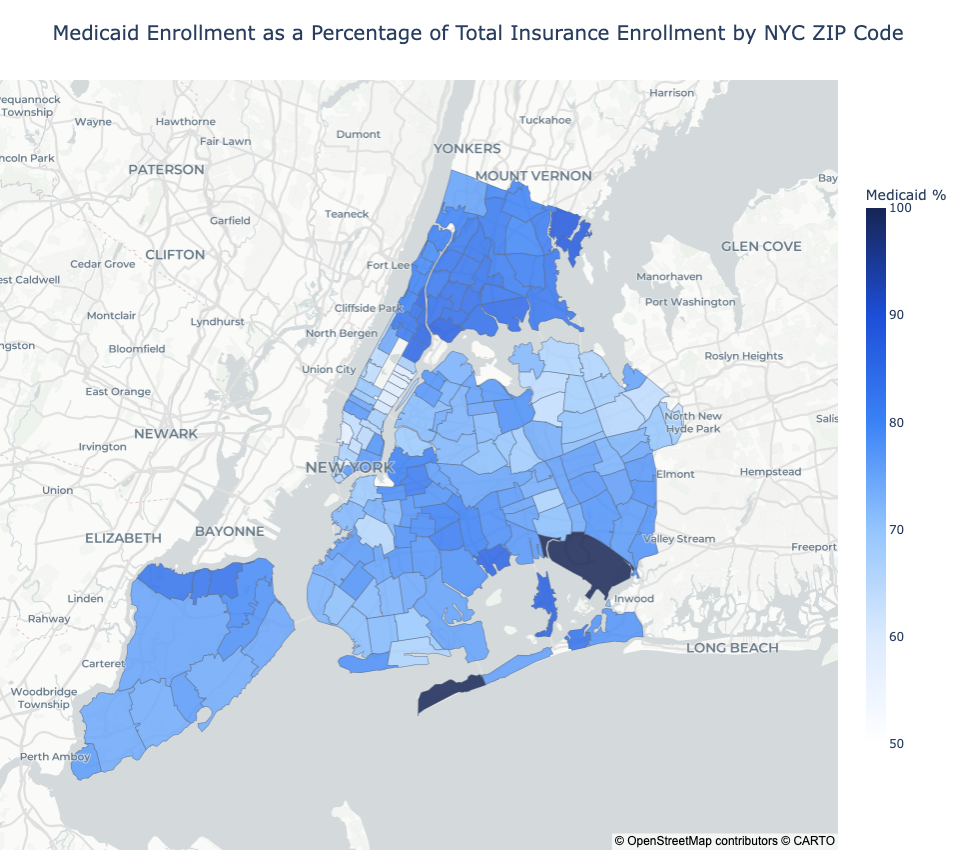

ZIP codes mapped: 181
Minimum Medicaid enrollment percentage: 57.57
Maximum Medicaid enrollment percentage: 100.0


,Zip_Code,Total_Enrollments,Medicaid Count,Medicaid Percentage
221,11697,146.0,146.0,100.000000
210,11430,86.0,86.0,100.000000
105,10464,692.0,609.0,88.005780
95,10454,20463.0,17809.0,87.030250
219,11693,3448.0,2999.0,86.977958
165,11239,4900.0,4228.0,86.285714
36,10039,10932.0,9411.0,86.086718
32,10035,13117.0,11218.0,85.522604
34,10037,6333.0,5400.0,85.267646
26,10029,30500.0,25960.0,85.114754


In [3]:

import pandas as pd
import numpy as np
import json
import plotly.express as px

# -----------------------------------------
# 1. LOAD DATA
# -----------------------------------------

program_zip_df = pd.read_csv(
    "NYC_Program_Enrollment_by_ZIP.csv",
    dtype={"Zip_Code": "string"}
)

with open(
    "nyc-zip-code-tabulation-areas-polygons.geojson",
    "r"
) as f:
    zip_geojson = json.load(f)

program_zip_df.columns = program_zip_df.columns.str.strip()

# -----------------------------------------
# 2. CLEAN ZIP CODES
# -----------------------------------------

program_zip_df["Zip_Code"] = (
    program_zip_df["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# -----------------------------------------
# 3. STANDARDIZE GEOJSON ZIP CODES
# -----------------------------------------

for feature in zip_geojson["features"]:
    feature["properties"]["Zip_Code"] = (
        str(feature["properties"]["postalCode"])
        .strip()
        .zfill(5)
    )

# -----------------------------------------
# 4. DEFINE INSURANCE PROGRAMS
# -----------------------------------------

program_types = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_columns = [
    f"{program} Count"
    for program in program_types
]

# -----------------------------------------
# 5. CLEAN ENROLLMENT COUNTS
# -----------------------------------------

for col in count_columns:
    program_zip_df[col] = pd.to_numeric(
        program_zip_df[col]
        .astype(str)
        .str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# -----------------------------------------
# 6. CALCULATE TOTAL ENROLLMENTS
# -----------------------------------------

program_zip_df["Total_Enrollments"] = (
    program_zip_df[count_columns].sum(axis=1)
)

# -----------------------------------------
# 7. CALCULATE ENROLLMENT PERCENTAGES
# -----------------------------------------

for program in program_types:

    program_zip_df[f"{program} Percentage"] = (
        program_zip_df[f"{program} Count"]
        / program_zip_df["Total_Enrollments"].replace(0, np.nan)
        * 100
    )

# -----------------------------------------
# 8. FILTER TO ZIP CODES IN GEOJSON
# -----------------------------------------

mapped_zips = {
    feature["properties"]["Zip_Code"]
    for feature in zip_geojson["features"]
}

map_df = program_zip_df[
    program_zip_df["Zip_Code"].isin(mapped_zips)
].copy()

# Exclude ZIP codes with zero enrollments
map_df = map_df[
    map_df["Total_Enrollments"] > 0
].copy()

# -----------------------------------------
# 9. DEFINE CUSTOM COLOR GRADIENT
# -----------------------------------------

# 50% = white
# 100% = darkest blue

medicaid_colors = [
    [0.00, "#FFFFFF"],  # 50%
    [0.20, "#DBEAFE"],  # 60%
    [0.40, "#93C5FD"],  # 70%
    [0.60, "#3B82F6"],  # 80%
    [0.80, "#1D4ED8"],  # 90%
    [1.00, "#172554"]   # 100%
]

# -----------------------------------------
# 10. DEFINE HOVER DATA
# -----------------------------------------

hover_columns = [
    "Zip_Code",
    "Total_Enrollments",

    "Medicaid Count",
    "Medicaid Percentage",

    "CHP Count",
    "CHP Percentage",

    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",

    "QHP Full Pay Count",
    "QHP Full Pay Percentage",

    "Essential Plan Count",
    "Essential Plan Percentage"
]

# -----------------------------------------
# 11. CREATE CHOROPLETH MAP
# -----------------------------------------

fig = px.choropleth_map(
    map_df,

    geojson=zip_geojson,

    locations="Zip_Code",

    featureidkey="properties.Zip_Code",

    color="Medicaid Percentage",

    color_continuous_scale=medicaid_colors,

    range_color=(50, 100),

    custom_data=hover_columns,

    map_style="carto-positron",

    center={
        "lat": 40.7128,
        "lon": -73.94
    },

    zoom=9.6,

    opacity=0.85,

    title=(
        "Medicaid Enrollment Percentage "
        "by NYC ZIP Code"
    ),

    height=850
)

# -----------------------------------------
# 12. CUSTOMIZE HOVER INFORMATION
# -----------------------------------------

fig.update_traces(
    hovertemplate=(
        "<b>ZIP Code: %{customdata[0]}</b><br>"
        "<br>"

        "<b>Total Insurance Enrollments:</b> "
        "%{customdata[1]:,.0f}<br>"

        "<br><b>MEDICAID</b><br>"
        "Enrollments: %{customdata[2]:,.0f}<br>"
        "Percentage: %{customdata[3]:.2f}%<br>"

        "<br><b>CHP</b><br>"
        "Enrollments: %{customdata[4]:,.0f}<br>"
        "Percentage: %{customdata[5]:.2f}%<br>"

        "<br><b>QHP APTC w/o CSR</b><br>"
        "Enrollments: %{customdata[6]:,.0f}<br>"
        "Percentage: %{customdata[7]:.2f}%<br>"

        "<br><b>QHP FULL PAY</b><br>"
        "Enrollments: %{customdata[8]:,.0f}<br>"
        "Percentage: %{customdata[9]:.2f}%<br>"

        "<br><b>ESSENTIAL PLAN</b><br>"
        "Enrollments: %{customdata[10]:,.0f}<br>"
        "Percentage: %{customdata[11]:.2f}%"

        "<extra></extra>"
    ),

    marker_line_width=0.6,
    marker_line_color="#64748B"
)

# -----------------------------------------
# 13. CUSTOMIZE COLORBAR
# -----------------------------------------

fig.update_layout(
    coloraxis_colorbar=dict(
        title="Medicaid %",
        ticksuffix="%",
        tickvals=[
            50, 60, 70, 80, 90, 100
        ],
        len=0.75,
        thickness=20
    )
)

# -----------------------------------------
# 14. CUSTOMIZE MAP LAYOUT
# -----------------------------------------

fig.update_layout(
    title=dict(
        text=(
            "Medicaid Enrollment as a Percentage "
            "of Total Insurance Enrollment "
            "by NYC ZIP Code"
        ),
        x=0.5,
        font=dict(size=20)
    ),

    margin=dict(
        l=0,
        r=0,
        t=80,
        b=0
    ),

    height=850,

    paper_bgcolor="white"
)

# -----------------------------------------
# 15. DISPLAY MAP
# -----------------------------------------

fig.show()

# -----------------------------------------
# 16. SAVE INTERACTIVE HTML MAP
# -----------------------------------------

fig.write_html(
    "NYC_Medicaid_Enrollment_Map.html"
)

# -----------------------------------------
# 17. CHECK RESULTS
# -----------------------------------------

print(
    "ZIP codes mapped:",
    map_df["Zip_Code"].nunique()
)

print(
    "Minimum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].min(), 2)
)

print(
    "Maximum Medicaid enrollment percentage:",
    round(map_df["Medicaid Percentage"].max(), 2)
)

display(
    map_df[
        [
            "Zip_Code",
            "Total_Enrollments",
            "Medicaid Count",
            "Medicaid Percentage"
        ]
    ].sort_values(
        "Medicaid Percentage",
        ascending=False
    ).head(15)
)


In [5]:

import pandas as pd
import numpy as np
import geopandas as gpd
import json
import plotly.graph_objects as go
from shapely import wkt
from pathlib import Path

# ==================================================
# 1. FILE SETTINGS
# ==================================================

ENROLLMENT_FILE = "NYC_Program_Enrollment_by_ZIP.csv"

ZIP_GEOJSON_FILE = (
    "nyc-zip-code-tabulation-areas-polygons.geojson"
)

DISTRICT_GEOJSON_FILE = "nyc_districts.geojson"

# Alternative polygon source, if the GeoJSON
# contains points rather than district boundaries
DISTRICT_CSV_FILE = "communitydistricts.csv"

# CHANGE THIS to the file containing your
# 2023 community district death rates.
DEATH_RATE_FILE = "CommunityDistrictDeathRates.csv"

# Expected death rate units: deaths per 1,000 residents.
# If your data uses deaths per 100,000, change
# the text in the labels accordingly.

RATE_UNIT = "deaths per 1,000 residents"

# ==================================================
# 2. LOAD ENROLLMENT DATA
# ==================================================

insurance = pd.read_csv(
    ENROLLMENT_FILE,
    dtype={"Zip_Code": "string"}
)

insurance.columns = insurance.columns.str.strip()

insurance["Zip_Code"] = (
    insurance["Zip_Code"]
    .astype("string")
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

programs = [
    "Medicaid",
    "CHP",
    "QHP APTC w/o CSR",
    "QHP Full Pay",
    "Essential Plan"
]

count_cols = [f"{p} Count" for p in programs]

missing = [
    c for c in count_cols
    if c not in insurance.columns
]

if missing:
    raise ValueError(
        f"Missing insurance columns: {missing}"
    )

insurance[count_cols] = (
    insurance[count_cols]
    .replace(",", "", regex=True)
    .apply(pd.to_numeric, errors="coerce")
)

# Keep missing counts missing rather than
# automatically treating them as zero.
insurance = insurance.dropna(subset=count_cols)

insurance = (
    insurance.groupby(
        "Zip_Code",
        as_index=False
    )[count_cols].sum()
)

insurance["Total_Enrollments"] = (
    insurance[count_cols].sum(axis=1)
)

insurance = insurance[
    insurance["Total_Enrollments"] > 0
].copy()

for program in programs:

    insurance[f"{program} Percentage"] = (
        insurance[f"{program} Count"]
        / insurance["Total_Enrollments"]
        * 100
    )

# ==================================================
# 3. LOAD ZIP CODE POLYGONS
# ==================================================

zip_gdf = gpd.read_file(ZIP_GEOJSON_FILE)

zip_gdf["Zip_Code"] = (
    zip_gdf["postalCode"]
    .astype("string")
    .str.strip()
    .str.zfill(5)
)

if zip_gdf.crs is None:
    raise ValueError(
        "ZIP GeoJSON has no coordinate reference system."
    )

zip_gdf = zip_gdf.to_crs("EPSG:4326")

zip_gdf = zip_gdf[
    zip_gdf.geometry.notna()
    & zip_gdf.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

zip_gdf = zip_gdf[
    ["Zip_Code", "geometry"]
].dissolve(
    by="Zip_Code",
    as_index=False
)

zip_gdf = zip_gdf.merge(
    insurance,
    on="Zip_Code",
    how="inner",
    validate="one_to_one"
)

# ==================================================
# 4. LOAD COMMUNITY DISTRICT POLYGONS
# ==================================================

district_gdf = gpd.read_file(
    DISTRICT_GEOJSON_FILE
)

# If the file contains point coordinates,
# try the alternative district boundary CSV.

has_polygons = district_gdf.geom_type.isin(
    ["Polygon", "MultiPolygon"]
).any()

if not has_polygons:

    if not Path(DISTRICT_CSV_FILE).exists():
        raise ValueError(
            "nyc_districts.geojson contains no district "
            "polygons. Provide a community district "
            "boundary GeoJSON, or communitydistricts.csv "
            "with the_geom and boro_cd columns."
        )

    cd_csv = pd.read_csv(
        DISTRICT_CSV_FILE
    )

    cd_csv.columns = cd_csv.columns.str.strip()

    if not {"boro_cd", "the_geom"}.issubset(
        cd_csv.columns
    ):
        raise ValueError(
            "communitydistricts.csv needs "
            "'boro_cd' and 'the_geom' columns."
        )

    district_gdf = gpd.GeoDataFrame(
        cd_csv,
        geometry=cd_csv["the_geom"].apply(
            lambda x: wkt.loads(x)
            if pd.notna(x) else None
        ),
        crs="EPSG:4326"
    )

# Standardize community district identifier

if "commntydst" not in district_gdf.columns:

    for candidate in [
        "boro_cd", "BoroCD", "BORO_CD"
    ]:
        if candidate in district_gdf.columns:
            district_gdf = district_gdf.rename(
                columns={
                    candidate: "commntydst"
                }
            )
            break

if "commntydst" not in district_gdf.columns:
    raise ValueError(
        "Community district identifier not found. "
        f"Columns: {district_gdf.columns.tolist()}"
    )

district_gdf["commntydst"] = pd.to_numeric(
    district_gdf["commntydst"],
    errors="coerce"
)

district_gdf = district_gdf.dropna(
    subset=["commntydst", "geometry"]
)

district_gdf["commntydst"] = (
    district_gdf["commntydst"].astype(int)
)

district_gdf = district_gdf[
    district_gdf.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

district_gdf = district_gdf.to_crs(
    "EPSG:4326"
)

district_gdf = (
    district_gdf[
        ["commntydst", "geometry"]
    ]
    .dissolve(
        by="commntydst",
        as_index=False
    )
)

# ==================================================
# 5. LOAD COMMUNITY DISTRICT DEATH RATES
# ==================================================

if not Path(DEATH_RATE_FILE).exists():
    raise FileNotFoundError(
        f"Cannot find {DEATH_RATE_FILE}. "
        "Set DEATH_RATE_FILE to your CSV "
        "containing community district death rates."
    )

rates = pd.read_csv(DEATH_RATE_FILE)

rates.columns = rates.columns.str.strip()

# Accept either district column name

if "Community_District" in rates.columns:
    rates = rates.rename(
        columns={
            "Community_District": "commntydst"
        }
    )

required = ["commntydst", "Death_Rate"]

missing = [
    c for c in required
    if c not in rates.columns
]

if missing:
    raise ValueError(
        f"Death rate file is missing {missing}. "
        f"Available columns: {rates.columns.tolist()}"
    )

rates["commntydst"] = pd.to_numeric(
    rates["commntydst"],
    errors="coerce"
)

rates["Death_Rate"] = pd.to_numeric(
    rates["Death_Rate"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

rates = rates.dropna(
    subset=["commntydst", "Death_Rate"]
).copy()

rates["commntydst"] = (
    rates["commntydst"].astype(int)
)

if rates["commntydst"].duplicated().any():
    raise ValueError(
        "Death rate file has multiple rows per "
        "community district. Aggregate counts and "
        "population before calculating rates."
    )

# Keep optional fields for hover
optional_cols = [
    "Total_Deaths",
    "Total_population"
]

available_optional = [
    c for c in optional_cols
    if c in rates.columns
]

for col in available_optional:
    rates[col] = pd.to_numeric(
        rates[col].astype(str).str.replace(
            ",", "", regex=False
        ),
        errors="coerce"
    )

district_gdf = district_gdf.merge(
    rates[
        required + available_optional
    ],
    on="commntydst",
    how="inner",
    validate="one_to_one"
)

if district_gdf.empty:
    raise ValueError(
        "No community districts matched "
        "between polygons and death rates."
    )

# ==================================================
# 6. SPATIAL INTERSECTION
# ==================================================

# Use a projected CRS for area calculations.
# EPSG:2263 is appropriate for NYC.

zip_projected = zip_gdf[
    ["Zip_Code", "geometry"]
].to_crs("EPSG:2263")

district_projected = district_gdf[
    ["commntydst", "Death_Rate", "geometry"]
].to_crs("EPSG:2263")

# Calculate polygon intersections

intersection = gpd.overlay(
    zip_projected,
    district_projected,
    how="intersection",
    keep_geom_type=True
)

intersection["Intersection_Area"] = (
    intersection.geometry.area
)

# Remove zero-area intersections

intersection = intersection[
    intersection["Intersection_Area"] > 0
].copy()

# Calculate each district's share of
# the mapped ZIP intersection area.

intersection["Weight"] = (
    intersection["Intersection_Area"]
    / intersection.groupby(
        "Zip_Code"
    )["Intersection_Area"].transform("sum")
)

intersection["Weighted_Rate"] = (
    intersection["Weight"]
    * intersection["Death_Rate"]
)

# Area-weighted district death rate
# associated with each ZIP

zip_mortality = (
    intersection.groupby(
        "Zip_Code",
        as_index=False
    )["Weighted_Rate"].sum()
)

zip_mortality = zip_mortality.rename(
    columns={
        "Weighted_Rate": "Estimated_Death_Rate"
    }
)

zip_gdf = zip_gdf.merge(
    zip_mortality,
    on="Zip_Code",
    how="left",
    validate="one_to_one"
)

# ==================================================
# 7. CALCULATE PURPLE OVERLAP INTENSITY
# ==================================================

# Normalize Medicaid percentage from 50 to 100.
# Values below 50 receive an intensity of zero.

zip_gdf["Medicaid_Intensity"] = (
    (
        zip_gdf["Medicaid Percentage"] - 50
    ) / 50
).clip(0, 1)

# Normalize estimated mortality rate
# against the observed range.

rate_min = zip_gdf[
    "Estimated_Death_Rate"
].min()

rate_max = zip_gdf[
    "Estimated_Death_Rate"
].max()

if rate_max > rate_min:

    zip_gdf["Mortality_Intensity"] = (
        (
            zip_gdf["Estimated_Death_Rate"]
            - rate_min
        ) / (rate_max - rate_min)
    ).clip(0, 1)

else:
    zip_gdf["Mortality_Intensity"] = 0.0

# Both dimensions must be high to produce
# a high overlap intensity.

zip_gdf["Overlap_Score"] = (
    zip_gdf["Medicaid_Intensity"]
    * zip_gdf["Mortality_Intensity"]
    * 100
)

# Preserve missing mortality estimates
zip_gdf.loc[
    zip_gdf["Estimated_Death_Rate"].isna(),
    "Overlap_Score"
] = np.nan

# ==================================================
# 8. CALCULATE COMMUNITY DISTRICT LABEL POINTS
# ==================================================

# Representative points stay inside the polygons.

district_points = (
    district_gdf
    .to_crs("EPSG:2263")
    .geometry
    .representative_point()
)

district_points = gpd.GeoSeries(
    district_points,
    crs="EPSG:2263"
).to_crs("EPSG:4326")

district_gdf["lat"] = district_points.y.to_numpy()
district_gdf["lon"] = district_points.x.to_numpy()

# ==================================================
# 9. PREPARE GEOJSON FOR PLOTLY
# ==================================================

zip_geojson_clean = json.loads(
    zip_gdf[
        ["Zip_Code", "geometry"]
    ].to_json()
)

district_geojson_clean = json.loads(
    district_gdf[
        ["commntydst", "geometry"]
    ].to_json()
)

# ==================================================
# 10. COLOR SCALES
# ==================================================

medicaid_colors = [
    [0.00, "#FFFFFF"],
    [0.20, "#DBEAFE"],
    [0.40, "#93C5FD"],
    [0.60, "#3B82F6"],
    [0.80, "#1D4ED8"],
    [1.00, "#172554"]
]

mortality_colors = [
    [0.00, "#FFF5F5"],
    [0.25, "#FECACA"],
    [0.50, "#F87171"],
    [0.75, "#DC2626"],
    [1.00, "#7F1D1D"]
]

overlap_colors = [
    [0.00, "#FFFFFF"],
    [0.20, "#EDE9FE"],
    [0.40, "#C4B5FD"],
    [0.60, "#A78BFA"],
    [0.80, "#7C3AED"],
    [1.00, "#4C1D95"]
]

# ==================================================
# 11. CREATE PLOTLY MAP
# ==================================================

fig = go.Figure()

# ------------------------------------------
# LAYER 1: BLUE MEDICAID ZIP CODES
# ------------------------------------------

hover_cols = [
    "Zip_Code",
    "Total_Enrollments",
    "Medicaid Count",
    "Medicaid Percentage",
    "CHP Count",
    "CHP Percentage",
    "QHP APTC w/o CSR Count",
    "QHP APTC w/o CSR Percentage",
    "QHP Full Pay Count",
    "QHP Full Pay Percentage",
    "Essential Plan Count",
    "Essential Plan Percentage"
]

fig.add_trace(
    go.Choroplethmap(
        geojson=zip_geojson_clean,
        locations=zip_gdf["Zip_Code"],
        featureidkey="properties.Zip_Code",

        z=zip_gdf["Medicaid Percentage"],

        colorscale=medicaid_colors,
        zmin=50,
        zmax=100,

        marker=dict(
            opacity=0.85,
            line=dict(
                width=0.5,
                color="#64748B"
            )
        ),

        customdata=zip_gdf[
            hover_cols
        ].to_numpy(),

        hovertemplate=(
            "<b>ZIP %{customdata[0]}</b><br>"
            "Total Enrollments: %{customdata[1]:,.0f}<br>"
            "<br>"
            "Medicaid: %{customdata[2]:,.0f} "
            "(%{customdata[3]:.2f}%)<br>"
            "CHP: %{customdata[4]:,.0f} "
            "(%{customdata[5]:.2f}%)<br>"
            "QHP APTC: %{customdata[6]:,.0f} "
            "(%{customdata[7]:.2f}%)<br>"
            "QHP Full Pay: %{customdata[8]:,.0f} "
            "(%{customdata[9]:.2f}%)<br>"
            "Essential Plan: %{customdata[10]:,.0f} "
            "(%{customdata[11]:.2f}%)"
            "<extra></extra>"
        ),

        colorbar=dict(
            title="Medicaid %",
            x=1.02,
            len=0.65
        ),

        name="Medicaid",
        visible=True
    )
)

# ------------------------------------------
# LAYER 2: RED MORTALITY DISTRICTS
# ------------------------------------------

fig.add_trace(
    go.Choroplethmap(
        geojson=district_geojson_clean,

        locations=(
            district_gdf["commntydst"].astype(str)
        ),

        featureidkey="properties.commntydst",

        z=district_gdf["Death_Rate"],

        colorscale=mortality_colors,

        zmin=district_gdf["Death_Rate"].min(),
        zmax=district_gdf["Death_Rate"].max(),

        marker=dict(
            opacity=0.80,
            line=dict(
                width=1,
                color="#991B1B"
            )
        ),

        customdata=district_gdf[
            ["commntydst", "Death_Rate"]
        ].to_numpy(),

        hovertemplate=(
            "<b>Community District %{customdata[0]}</b><br>"
            "2023 Death Rate: %{customdata[1]:.2f}<br>"
            + RATE_UNIT +
            "<extra></extra>"
        ),

        colorbar=dict(
            title="Death Rate",
            x=1.02,
            len=0.65
        ),

        name="Mortality",
        visible=False
    )
)

# ------------------------------------------
# LAYER 3: PURPLE ZIP OVERLAP
# ------------------------------------------

fig.add_trace(
    go.Choroplethmap(
        geojson=zip_geojson_clean,

        locations=zip_gdf["Zip_Code"],

        featureidkey="properties.Zip_Code",

        z=zip_gdf["Overlap_Score"],

        colorscale=overlap_colors,

        zmin=0,
        zmax=100,

        marker=dict(
            opacity=0.88,
            line=dict(
                width=0.5,
                color="#6D28D9"
            )
        ),

        customdata=zip_gdf[
            [
                "Zip_Code",
                "Medicaid Percentage",
                "Estimated_Death_Rate",
                "Overlap_Score"
            ]
        ].to_numpy(),

        hovertemplate=(
            "<b>ZIP %{customdata[0]}</b><br>"
            "Medicaid Enrollment: "
            "%{customdata[1]:.2f}%<br>"
            "Estimated Death Rate: "
            "%{customdata[2]:.2f}<br>"
            + RATE_UNIT + "<br>"
            "Overlap Intensity: "
            "%{customdata[3]:.1f}/100"
            "<extra></extra>"
        ),

        colorbar=dict(
            title="Overlap",
            x=1.02,
            len=0.65
        ),

        name="Overlap",
        visible=False
    )
)

# ------------------------------------------
# LAYER 4: NUMERIC DEATH RATE LABELS
# ------------------------------------------

# Show rate labels at representative
# points inside each community district.

label_custom = district_gdf[
    ["commntydst", "Death_Rate"]
].to_numpy()

fig.add_trace(
    go.Scattermap(
        lat=district_gdf["lat"],
        lon=district_gdf["lon"],

        mode="markers+text",

        text=[
            f"{rate:.1f}"
            for rate in district_gdf["Death_Rate"]
        ],

        textposition="top center",

        textfont=dict(
            size=11,
            color="#7F1D1D"
        ),

        marker=dict(
            size=8,
            color="#DC2626",
            opacity=0.95
        ),

        customdata=label_custom,

        hovertemplate=(
            "<b>Community District "
            "%{customdata[0]}</b><br>"
            "Death Rate: %{customdata[1]:.2f}<br>"
            + RATE_UNIT +
            "<extra></extra>"
        ),

        name="District Death Rates",
        visible=False,
        showlegend=False
    )
)

# ==================================================
# 12. LAYER TOGGLE BUTTONS
# ==================================================

# Trace order:
# 0 Medicaid
# 1 Mortality
# 2 Overlap
# 3 Death rate labels

fig.update_layout(
    updatemenus=[
        dict(
            type="buttons",
            direction="right",

            buttons=[
                dict(
                    label="Medicaid",
                    method="update",
                    args=[
                        {
                            "visible": [
                                True, False,
                                False, False
                            ]
                        }
                    ]
                ),

                dict(
                    label="Mortality",
                    method="update",
                    args=[
                        {
                            "visible": [
                                False, True,
                                False, True
                            ]
                        }
                    ]
                ),

                dict(
                    label="Overlap",
                    method="update",
                    args=[
                        {
                            "visible": [
                                False, False,
                                True, False
                            ]
                        }
                    ]
                ),

                dict(
                    label="All Layers",
                    method="update",
                    args=[
                        {
                            "visible": [
                                False, False,
                                True, True
                            ]
                        }
                    ]
                )
            ],

            x=0.01,
            y=1.06,
            xanchor="left",
            yanchor="bottom",
            showactive=True
        )
    ]
)

# ==================================================
# 13. MAP LAYOUT
# ==================================================

fig.update_layout(
    map=dict(
        style="carto-positron",

        center=dict(
            lat=40.7128,
            lon=-73.94
        ),

        zoom=9.6
    ),

    title=dict(
        text=(
            "NYC Medicaid Enrollment, "
            "2023 Mortality Rates, and Geographic Overlap"
        ),
        x=0.5,
        font=dict(size=19)
    ),

    height=900,

    margin=dict(
        l=0,
        r=90,
        t=110,
        b=0
    ),

    paper_bgcolor="white",

    showlegend=True
)

# ==================================================
# 14. DISPLAY AND SAVE
# ==================================================

fig.show()

fig.write_html(
    "NYC_Medicaid_Mortality_Overlap_Map.html"
)

# ==================================================
# 15. CHECK RESULTS
# ==================================================

print(
    "ZIP codes mapped:",
    zip_gdf["Zip_Code"].nunique()
)

print(
    "Community districts mapped:",
    district_gdf["commntydst"].nunique()
)

print(
    "ZIP codes with mortality estimates:",
    zip_gdf["Estimated_Death_Rate"].notna().sum()
)

display(
    zip_gdf[
        [
            "Zip_Code",
            "Medicaid Percentage",
            "Estimated_Death_Rate",
            "Overlap_Score"
        ]
    ].sort_values(
        "Overlap_Score",
        ascending=False
    ).head(15)
)


FileNotFoundError: Cannot find CommunityDistrictDeathRates.csv. Set DEATH_RATE_FILE to your CSV containing community district death rates.